# RelAmazon subset: exploratory data analysis

This notebook profiles the local RelAmazon subset used by SimBench: table schemas, data quality, missingness, attribute distributions, review text, temporal coverage, foreign-key integrity, and the customer–product review graph. It reads the three local Parquet files directly and makes no changes to the dataset.

In [40]:
from pathlib import Path
from collections import Counter
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import yaml
from IPython.display import Markdown, display

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_rows', 100)

REPO = Path.cwd().resolve()
if not (REPO / 'data' / 'dev' / 'rel-amazon').exists():
    REPO = Path('/storage/lcostes/Similarity_benchmark')
DATASET_ROOT = REPO / 'data' / 'dev' / 'rel-amazon'
MANIFEST = yaml.safe_load((DATASET_ROOT / 'manifest.yaml').read_text())

def read_table(name, columns=None):
    return pq.read_table(DATASET_ROOT / f'{name}.parquet', columns=columns).to_pandas()

tables = {name: read_table(name) for name in MANIFEST['tables']}
customer, product, review = tables['customer'], tables['product'], tables['review']
review['review_time'] = pd.to_datetime(review['review_time'], errors='coerce')

display(Markdown(f"**Dataset:** `{MANIFEST['name']}`  \n**Description:** {MANIFEST['description']}  \n**Validation timestamp:** `{MANIFEST['val_timestamp']}` · **test timestamp:** `{MANIFEST['test_timestamp']}`"))

**Dataset:** `rel-amazon`  
**Description:** Amazon product reviews: customers, products, and time-stamped reviews and ratings across the Amazon catalog.  
**Validation timestamp:** `2015-10-01` · **test timestamp:** `2016-01-01`

## Schema and relational graph

`review` is the event/edge table. Each row connects one `customer` to one `product`, and stores the rating, verification flag, text, summary, and time. The table therefore induces a bipartite customer–product graph.

```text
customer (customer_id)  ←── review.customer_id ──  review  ── review.product_id ──→  product (product_id)
                                  |  time, rating, verified, text, summary
```

In [41]:
inventory = []
for name, schema in MANIFEST['tables'].items():
    parquet = DATASET_ROOT / f'{name}.parquet'
    pf = pq.ParquetFile(parquet)
    frame = tables[name]
    inventory.append({
        'table': name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'primary key': schema['pkey'] or '—',
        'time column': schema['time_col'] or '—',
        'foreign keys': ', '.join(f"{col} → {target}" for col, target in schema['fkeys'].items()) or '—',
        'file size (MiB)': round(parquet.stat().st_size / 2**20, 2),
        'row groups': pf.num_row_groups,
    })
display(Markdown('## Table inventory'))
display(pd.DataFrame(inventory))

schema_rows = []
for name, frame in tables.items():
    for col, dtype in frame.dtypes.items():
        schema_rows.append({'table': name, 'column': col, 'pandas dtype': str(dtype)})
display(Markdown('### Column types'))
display(pd.DataFrame(schema_rows))

## Table inventory

,table,rows,columns,primary key,time column,foreign keys,file size (MiB),row groups
0,review,50000,7,—,review_time,"customer_id → customer, product_id → product",10.99,1
1,product,500,6,product_id,—,—,0.25,1
2,customer,43948,2,customer_id,—,—,0.61,1


### Column types

,table,column,pandas dtype
0,review,review_time,datetime64[ns]
1,review,customer_id,int64
2,review,product_id,int64
3,review,rating,float32
4,review,verified,bool
5,review,review_text,str
6,review,summary,str
7,product,product_id,int64
8,product,category,object
9,product,brand,str


In [42]:
# Exact missingness, including blank strings and empty lists.
def missing_or_blank(series):
    missing = series.isna()
    if pd.api.types.is_string_dtype(series) or series.dtype == object:
        non_null = series[~missing]
        if len(non_null):
            first = non_null.iloc[0]
            if isinstance(first, str):
                missing = missing | series.fillna('').astype(str).str.strip().eq('')
            elif isinstance(first, (list, tuple, np.ndarray)):
                missing = missing | series.map(lambda value: isinstance(value, (list, tuple, np.ndarray)) and len(value) == 0)
    return missing

def non_null_distinct(series):
    values = series.dropna()
    if len(values) and isinstance(values.iloc[0], (list, tuple, np.ndarray)):
        # Category is a list-valued attribute; count distinct category entries, not unhashable lists.
        values = values.explode().dropna()
    return int(values.nunique())

missing_rows = []
for name, frame in tables.items():
    for col in frame.columns:
        count = int(missing_or_blank(frame[col]).sum())
        missing_rows.append({
            'table': name, 'column': col, 'missing / blank': count,
            'missing rate': count / len(frame),
            'non-null distinct': non_null_distinct(frame[col]),
        })
missingness = pd.DataFrame(missing_rows).sort_values(['missing rate', 'table'], ascending=[False, True])
display(Markdown('## Completeness and cardinality'))
display(missingness.style.format({'missing rate': '{:.2%}'}).background_gradient(subset=['missing rate'], cmap='Reds'))

## Completeness and cardinality

,table,column,missing / blank,missing rate,non-null distinct
11,product,description,173,34.60%,314
8,product,category,60,12.00%,72
9,product,brand,10,2.00%,317
6,review,summary,8,0.02%,31491
5,review,review_text,5,0.01%,48150
13,customer,customer_id,0,0.00%,43948
14,customer,customer_name,0,0.00%,35543
7,product,product_id,0,0.00%,500
10,product,title,0,0.00%,492
12,product,price,0,0.00%,347


In [43]:
# Primary-key, duplicate-row, and foreign-key checks.
def exact_duplicate_count(frame):
    # Pandas cannot hash list/ndarray cells (for example product.category).
    comparable = frame.copy()
    for column in comparable.columns:
        if comparable[column].dtype == object:
            comparable[column] = comparable[column].map(
                lambda value: tuple(value.tolist()) if isinstance(value, np.ndarray)
                else tuple(value) if isinstance(value, (list, tuple))
                else value
            )
    return int(comparable.duplicated().sum())

quality_rows = []
for name, frame in tables.items():
    pkey = MANIFEST['tables'][name]['pkey']
    quality_rows.append({
        'table': name,
        'exact duplicate rows': exact_duplicate_count(frame),
        'primary key': pkey or '—',
        'missing primary keys': int(frame[pkey].isna().sum()) if pkey else '—',
        'duplicate primary keys': int(frame[pkey].duplicated().sum()) if pkey else '—',
    })
display(Markdown('## Keys and duplicate rows'))
display(pd.DataFrame(quality_rows))

fk_checks = pd.DataFrame([
    {
        'foreign key': 'review.customer_id → customer.customer_id',
        'review rows': len(review),
        'missing FK value': int(review['customer_id'].isna().sum()),
        'orphan values': int((~review['customer_id'].isin(customer['customer_id'])).sum()),
    },
    {
        'foreign key': 'review.product_id → product.product_id',
        'review rows': len(review),
        'missing FK value': int(review['product_id'].isna().sum()),
        'orphan values': int((~review['product_id'].isin(product['product_id'])).sum()),
    },
])
display(Markdown('### Referential integrity'))
display(fk_checks)

repeat_edges = review.duplicated(['customer_id', 'product_id']).sum()
display(Markdown(f"Repeated customer–product review pairs: **{repeat_edges:,}** of {len(review):,} review rows. These are repeated interactions, not necessarily duplicate rows."))

## Keys and duplicate rows

,table,exact duplicate rows,primary key,missing primary keys,duplicate primary keys
0,review,5,—,—,—
1,product,0,product_id,0,0
2,customer,0,customer_id,0,0


### Referential integrity

,foreign key,review rows,missing FK value,orphan values
0,review.customer_id → customer.customer_id,50000,0,0
1,review.product_id → product.product_id,50000,0,0


Repeated customer–product review pairs: **44** of 50,000 review rows. These are repeated interactions, not necessarily duplicate rows.

In [44]:
display(Markdown('## Numeric and temporal distributions\n\nEntity and foreign-key identifiers (columns ending in `_id`) are intentionally excluded: their magnitudes and quantiles have no numeric meaning.'))
numeric_frames = []
for name, frame in tables.items():
    numeric = frame.select_dtypes(include=['number', 'bool']).drop(columns=[column for column in frame.columns if column.endswith('_id')], errors='ignore')
    if not numeric.empty:
        summary = numeric.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.reset_index(names='column')
        summary.insert(0, 'table', name)
        numeric_frames.append(summary)
display(pd.concat(numeric_frames, ignore_index=True).round(3))
display(pd.DataFrame([{
    'earliest review': review['review_time'].min(),
    'latest review': review['review_time'].max(),
    'reviews before validation': int((review['review_time'] < pd.Timestamp(MANIFEST['val_timestamp'])).sum()),
    'validation interval': int(((review['review_time'] >= pd.Timestamp(MANIFEST['val_timestamp'])) & (review['review_time'] < pd.Timestamp(MANIFEST['test_timestamp']))).sum()),
    'test-or-later': int((review['review_time'] >= pd.Timestamp(MANIFEST['test_timestamp'])).sum()),
}]))

## Numeric and temporal distributions

Entity and foreign-key identifiers (columns ending in `_id`) are intentionally excluded: their magnitudes and quantiles have no numeric meaning.

,table,column,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,review,rating,50000.0,4.330,1.002,1.00,1.00,2.00,4.000,5.00,5.000,5.000,5.0,5.00
1,product,price,500.0,18.121,35.425,1.51,1.97,5.49,9.662,11.99,16.428,38.526,100.8,597.65


,earliest review,latest review,reviews before validation,validation interval,test-or-later
0,2008-01-01,2018-07-06,26807,3832,19361


In [45]:
display(Markdown('## Categorical attributes and common values'))
def top_values(series, n=12):
    values = series.dropna()
    if len(values) and isinstance(values.iloc[0], (list, tuple, np.ndarray)):
        values = values.explode().dropna()
    return values.astype(str).value_counts().head(n).rename_axis('value').reset_index(name='count')

for table_name, column in [
    ('product', 'category'), ('product', 'brand'), ('review', 'rating'), ('review', 'verified'),
]:
    display(Markdown(f"### `{table_name}.{column}`"))
    display(top_values(tables[table_name][column]))

## Categorical attributes and common values

### `product.category`

,value,count
0,Books,440
1,Literature &amp; Fiction,162
2,Genre Fiction,117
3,"Mystery, Thriller &amp; Suspense",108
4,Thrillers &amp; Suspense,97
5,Literature & Fiction,49
6,"Mystery, Thriller & Suspense",35
7,Thrillers & Suspense,32
8,Women's Fiction,17
9,Contemporary,16


### `product.brand`

,value,count
0,Visit Amazon's Lee Child Page,15
1,,10
2,Visit Amazon's John Grisham Page,9
3,Visit Amazon's David Baldacci Page,9
4,Visit Amazon's James Patterson Page,8
5,Visit Amazon's John Sandford Page,7
6,Visit Amazon's Nora Roberts Page,7
7,Visit Amazon's Daniel Silva Page,6
8,Visit Amazon's Stephen King Page,6
9,Visit Amazon's Michael Connelly Page,6


### `review.rating`

,value,count
0,5.0,29749
1,4.0,11842
2,3.0,4991
3,2.0,1978
4,1.0,1440


### `review.verified`

,value,count
0,True,38617
1,False,11383


## Text coverage and length

,field,empty,mean chars,median chars,p95 chars,max chars
0,product.title,0,32.9,28.5,83.0,128
1,product.description,173,782.8,299.0,2903.7,17555
2,review.summary,8,23.1,17.0,60.0,299
3,review.review_text,5,328.9,158.0,1261.0,15831


### Short, truncated examples

,rating,verified,summary,review_text
0,4.0,True,"If you love italy , you'll enjoy this novel","A charming escape back to Italy. The main characters discoveries and the people he met, brought back only the best o..."
1,4.0,False,A Different Book for Grisham,"I'll confess, I'm no sports fan. I don't understand a thing about football but I really enjoyed this book. The char..."
2,5.0,True,"Simply, one of the best","This is one of the best books I have read. I remembered Ken Follett's ""Pillars of the Earth"", and was astonished to ..."
3,5.0,True,Best Book of 2005,Others have said what all the amazing things are about this book. It's wonderfully crafted and truly entertaining. D...
4,5.0,True,This book will haunt you after you read it,I don't really know where to start with this book review. This book made me cry and it terrified me with its treatme...


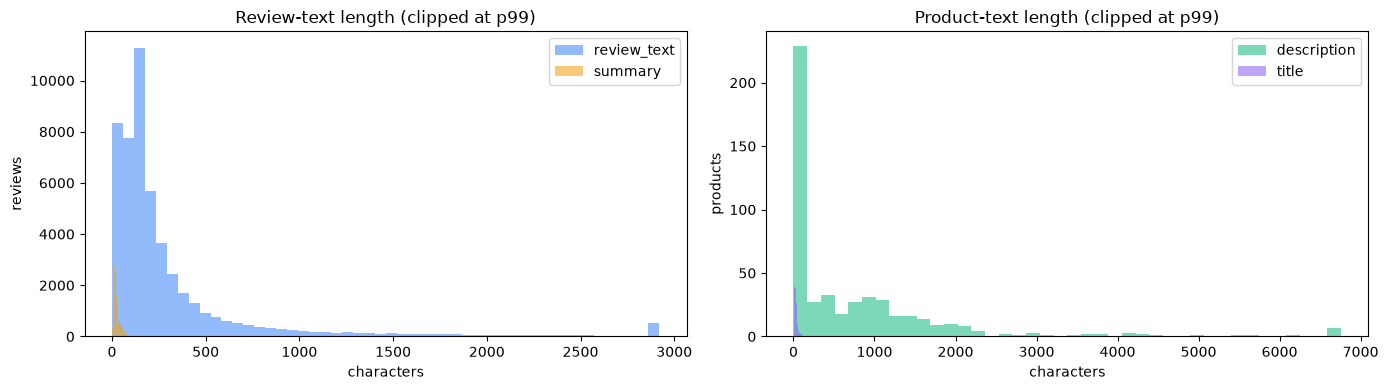

In [46]:
# Text fields: length is a useful proxy for how much evidence the text signals can carry.
text_columns = [('product', 'title'), ('product', 'description'), ('review', 'summary'), ('review', 'review_text')]
text_stats = []
for table_name, column in text_columns:
    values = tables[table_name][column].fillna('').astype(str)
    lengths = values.str.len()
    text_stats.append({
        'field': f'{table_name}.{column}', 'empty': int(values.str.strip().eq('').sum()),
        'mean chars': lengths.mean(), 'median chars': lengths.median(),
        'p95 chars': lengths.quantile(.95), 'max chars': lengths.max(),
    })
display(Markdown('## Text coverage and length'))
display(pd.DataFrame(text_stats).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for column, color in [('review_text', '#3b82f6'), ('summary', '#f59e0b')]:
    lengths = review[column].fillna('').astype(str).str.len()
    axes[0].hist(np.clip(lengths, 0, lengths.quantile(.99)), bins=50, alpha=.55, label=column, color=color)
axes[0].set(title='Review-text length (clipped at p99)', xlabel='characters', ylabel='reviews')
axes[0].legend()
for column, color in [('description', '#10b981'), ('title', '#8b5cf6')]:
    lengths = product[column].fillna('').astype(str).str.len()
    axes[1].hist(np.clip(lengths, 0, lengths.quantile(.99)), bins=40, alpha=.55, label=column, color=color)
axes[1].set(title='Product-text length (clipped at p99)', xlabel='characters', ylabel='products')
axes[1].legend()
plt.tight_layout()

display(Markdown('### Short, truncated examples'))
display(review[['rating', 'verified', 'summary', 'review_text']].head(5).assign(
    summary=lambda df: df['summary'].astype(str).str.slice(0, 160),
    review_text=lambda df: df['review_text'].astype(str).str.slice(0, 240),
))

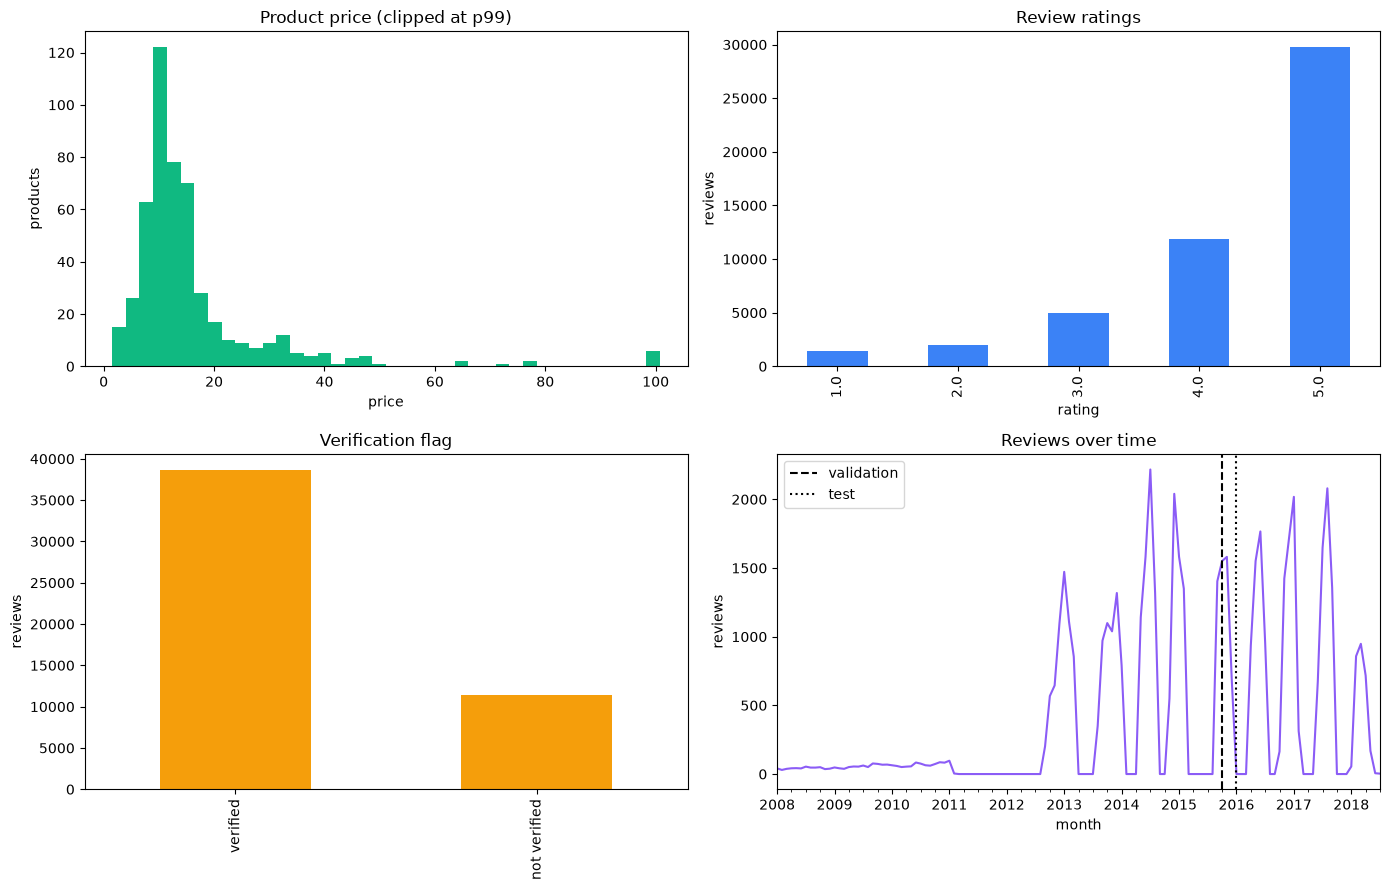

In [47]:
# Distribution plots for price, ratings, verification, and review time.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
price = product['price'].dropna()
axes[0, 0].hist(np.clip(price, 0, price.quantile(.99)), bins=40, color='#10b981')
axes[0, 0].set(title='Product price (clipped at p99)', xlabel='price', ylabel='products')
review['rating'].value_counts().sort_index().plot.bar(ax=axes[0, 1], color='#3b82f6')
axes[0, 1].set(title='Review ratings', xlabel='rating', ylabel='reviews')
review['verified'].value_counts(dropna=False).rename(index={True: 'verified', False: 'not verified'}).plot.bar(ax=axes[1, 0], color='#f59e0b')
axes[1, 0].set(title='Verification flag', xlabel='', ylabel='reviews')
monthly = review.dropna(subset=['review_time']).set_index('review_time').resample('MS').size()
monthly.plot(ax=axes[1, 1], color='#8b5cf6')
axes[1, 1].axvline(pd.Timestamp(MANIFEST['val_timestamp']), color='black', linestyle='--', label='validation')
axes[1, 1].axvline(pd.Timestamp(MANIFEST['test_timestamp']), color='black', linestyle=':', label='test')
axes[1, 1].set(title='Reviews over time', xlabel='month', ylabel='reviews')
axes[1, 1].legend()
plt.tight_layout()

## Customer–product graph

,customer nodes,product nodes,review rows / multiedges,distinct customer–product edges,customers with >=1 review,products with >=1 review,bipartite density,mean reviews per active customer,mean reviews per active product
0,43948,500,50000,49956,43948,500,0.22734%,1.14,100.00


### Degree summary

,customer degree,product degree
count,43948.00,500.0
mean,1.14,100.0
std,0.42,0.0
min,1.00,100.0
50%,1.00,100.0
90%,2.00,100.0
95%,2.00,100.0
99%,3.00,100.0
max,14.00,100.0


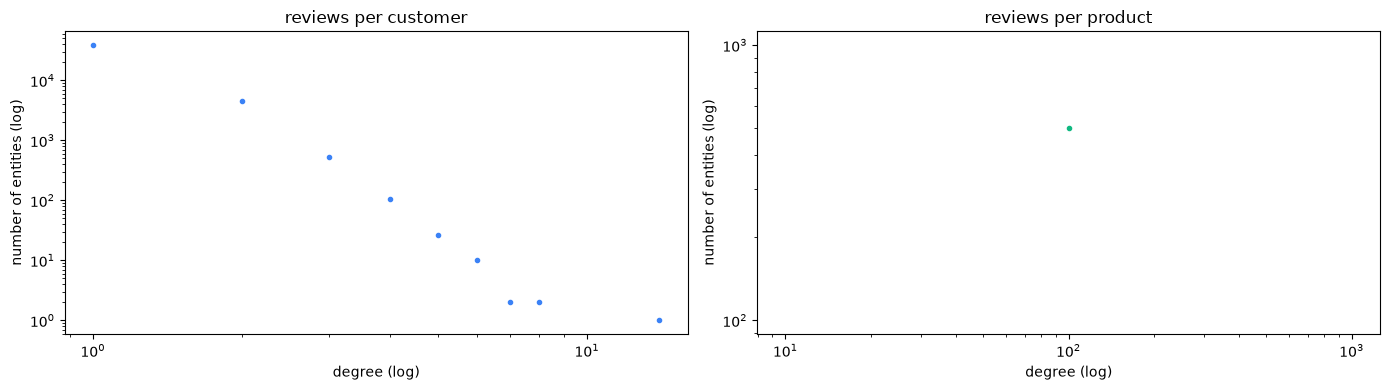

In [48]:
# The review table creates a customer–product bipartite graph.
customer_degree = review.groupby('customer_id').size().rename('reviews per customer')
product_degree = review.groupby('product_id').size().rename('reviews per product')
unique_customer_product = review[['customer_id', 'product_id']].drop_duplicates()
graph_summary = pd.DataFrame([{
    'customer nodes': len(customer),
    'product nodes': len(product),
    'review rows / multiedges': len(review),
    'distinct customer–product edges': len(unique_customer_product),
    'customers with >=1 review': review['customer_id'].nunique(),
    'products with >=1 review': review['product_id'].nunique(),
    'bipartite density': len(unique_customer_product) / (len(customer) * len(product)),
    'mean reviews per active customer': customer_degree.mean(),
    'mean reviews per active product': product_degree.mean(),
}])
display(Markdown('## Customer–product graph'))
display(graph_summary.style.format({'bipartite density': '{:.5%}', 'mean reviews per active customer': '{:.2f}', 'mean reviews per active product': '{:.2f}'}))

degree_summary = pd.concat([
    customer_degree.describe(percentiles=[.5, .9, .95, .99]).rename('customer degree'),
    product_degree.describe(percentiles=[.5, .9, .95, .99]).rename('product degree'),
], axis=1)
display(Markdown('### Degree summary'))
display(degree_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for degree, label, color in [(customer_degree, 'reviews per customer', '#3b82f6'), (product_degree, 'reviews per product', '#10b981')]:
    counts = degree.value_counts().sort_index()
    axes[0 if label.startswith('reviews per customer') else 1].loglog(counts.index, counts.values, marker='.', linestyle='none', color=color)
    axes[0 if label.startswith('reviews per customer') else 1].set(title=label, xlabel='degree (log)', ylabel='number of entities (log)')
plt.tight_layout()

In [49]:
# Product-level behavior: how much review evidence exists for each product?
product_behavior = (review.groupby('product_id')
    .agg(review_count=('rating', 'size'), unique_customers=('customer_id', 'nunique'),
         mean_rating=('rating', 'mean'), median_rating=('rating', 'median'),
         verified_rate=('verified', 'mean'), first_review=('review_time', 'min'), last_review=('review_time', 'max'))
    .reset_index())
product_profile = product.merge(product_behavior, on='product_id', how='left')
display(Markdown('## Product-level review evidence'))
display(product_profile[['review_count', 'unique_customers', 'mean_rating', 'verified_rate']].describe(percentiles=[.1, .25, .5, .75, .9, .99]).T.round(3))

category_behavior = (product_profile.explode('category').groupby('category')
    .agg(products=('product_id', 'size'), median_price=('price', 'median'), mean_rating=('mean_rating', 'mean'), median_reviews=('review_count', 'median'))
    .sort_values('products', ascending=False).head(20))
display(Markdown('### Largest product categories'))
display(category_behavior.round(3))

correlations = product_profile[['price', 'review_count', 'unique_customers', 'mean_rating', 'verified_rate']].corr(numeric_only=True)
display(Markdown('### Product-level correlations'))
display(correlations.style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1).format('{:.2f}'))

## Product-level review evidence

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
review_count,500.0,100.000,0.000,100.00,100.000,100.000,100.00,100.00,100.00,100.00,100.0
unique_customers,500.0,99.912,0.425,96.00,100.000,100.000,100.00,100.00,100.00,100.00,100.0
mean_rating,500.0,4.330,0.291,3.16,3.989,4.168,4.36,4.54,4.68,4.84,4.9
verified_rate,500.0,0.772,0.137,0.18,0.579,0.710,0.81,0.87,0.92,0.98,1.0


### Largest product categories

,products,median_price,mean_rating,median_reviews
category,,,,
Books,440,11.990,4.331,100.0
Literature &amp; Fiction,162,11.055,4.333,100.0
Genre Fiction,117,11.000,4.336,100.0
"Mystery, Thriller &amp; Suspense",108,11.990,4.283,100.0
Thrillers &amp; Suspense,97,12.770,4.290,100.0
Literature & Fiction,49,12.800,4.373,100.0
"Mystery, Thriller & Suspense",35,11.990,4.259,100.0
Thrillers & Suspense,32,11.990,4.282,100.0
Women's Fiction,17,10.990,4.208,100.0


### Product-level correlations

,price,review_count,unique_customers,mean_rating,verified_rate
price,1.00,nan,-0.05,0.03,0.01
review_count,nan,nan,nan,nan,nan
unique_customers,-0.05,nan,1.00,-0.08,0.05
mean_rating,0.03,nan,-0.08,1.00,0.04
verified_rate,0.01,nan,0.05,0.04,1.00


## Connectivity

,connected components,largest component nodes,largest component share,isolated nodes
0,1,44448,100.00%,0


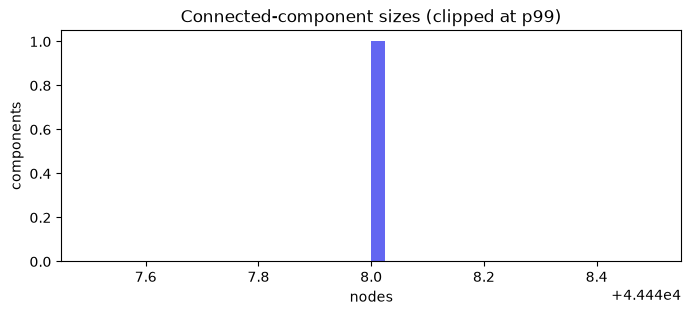

In [50]:
# Connected components quantify whether relationship paths can reach much of the graph.
try:
    import networkx as nx
    graph = nx.Graph()
    graph.add_nodes_from((f'customer:{value}' for value in customer['customer_id']), bipartite='customer')
    graph.add_nodes_from((f'product:{value}' for value in product['product_id']), bipartite='product')
    graph.add_edges_from((f'customer:{row.customer_id}', f'product:{row.product_id}') for row in unique_customer_product.itertuples(index=False))
    component_sizes = sorted((len(component) for component in nx.connected_components(graph)), reverse=True)
    component_report = pd.DataFrame([{
        'connected components': len(component_sizes),
        'largest component nodes': component_sizes[0] if component_sizes else 0,
        'largest component share': (component_sizes[0] / graph.number_of_nodes()) if component_sizes else 0,
        'isolated nodes': sum(size == 1 for size in component_sizes),
    }])
    display(Markdown('## Connectivity'))
    display(component_report.style.format({'largest component share': '{:.2%}'}))
    plt.figure(figsize=(8, 3))
    plt.hist(np.clip(component_sizes, 1, np.quantile(component_sizes, .99)), bins=40, color='#6366f1')
    plt.title('Connected-component sizes (clipped at p99)')
    plt.xlabel('nodes')
    plt.ylabel('components')
    plt.show()
except ImportError:
    print('Install networkx in the notebook environment to run the connected-components section.')

In [51]:
# Compact automatically computed checklist for using this subset in signal and similarity experiments.
active_product_share = review['product_id'].nunique() / len(product)
active_customer_share = review['customer_id'].nunique() / len(customer)
print(f'Products with review evidence: {active_product_share:.1%}')
print(f'Customers with review evidence: {active_customer_share:.1%}')
print(f'Product review-degree p50/p90/p99: {product_degree.quantile(.5):.0f} / {product_degree.quantile(.9):.0f} / {product_degree.quantile(.99):.0f}')
print(f'Customer review-degree p50/p90/p99: {customer_degree.quantile(.5):.0f} / {customer_degree.quantile(.9):.0f} / {customer_degree.quantile(.99):.0f}')
print(f'Reviews with non-empty text: {(review.review_text.fillna("").str.strip().ne("")).mean():.1%}')
print(f'Reviews with non-empty summaries: {(review.summary.fillna("").str.strip().ne("")).mean():.1%}')

display(Markdown('''## How to use the findings

- Use the **missingness** and **available signal components** to distinguish an unavailable attribute from a genuine low similarity.
- Use the **degree plots** to interpret relationship-path signals: low-degree entities have little relational evidence, while high-degree entities can dominate overlap measures.
- Use the **temporal panel** to keep signal construction and any future retrieval/similarity evaluation within the intended train/validation/test period.
- Use the **text-length and coverage** results before assuming that `review_text`, `summary`, `title`, or `description` are equally informative.
- Use the **foreign-key and connectivity checks** before interpreting multi-hop paths as evidence that is available for every entity.
'''))

Products with review evidence: 100.0%
Customers with review evidence: 100.0%
Product review-degree p50/p90/p99: 100 / 100 / 100
Customer review-degree p50/p90/p99: 1 / 2 / 3
Reviews with non-empty text: 100.0%
Reviews with non-empty summaries: 100.0%


## How to use the findings

- Use the **missingness** and **available signal components** to distinguish an unavailable attribute from a genuine low similarity.
- Use the **degree plots** to interpret relationship-path signals: low-degree entities have little relational evidence, while high-degree entities can dominate overlap measures.
- Use the **temporal panel** to keep signal construction and any future retrieval/similarity evaluation within the intended train/validation/test period.
- Use the **text-length and coverage** results before assuming that `review_text`, `summary`, `title`, or `description` are equally informative.
- Use the **foreign-key and connectivity checks** before interpreting multi-hop paths as evidence that is available for every entity.


## Search and inspect an entity

Choose a table and field, then search for text (for example, part of a product title) or select a category/value. Choose a result to inspect its attributes. For a product, the browser also summarizes its reviews and lets you inspect each related review.


In [ ]:
display(Markdown('## Search and inspect an entity\n\nChoose a table and field, then search for text (for example, part of a product title) or select a category/value. Choose a result to inspect all attributes of that record.'))

try:
    import html
    import ipywidgets as widgets
except ImportError:
    print('Install ipywidgets in this notebook kernel to use the entity search.')
else:
    table_picker = widgets.Dropdown(
        options=list(tables),
        value='product' if 'product' in tables else next(iter(tables)),
        description='Table:',
    )
    field_picker = widgets.Dropdown(description='Field:')
    mode_picker = widgets.Dropdown(
        options=[('Text contains', 'contains'), ('Exact match', 'exact'), ('Select category/value', 'select')],
        value='contains', description='Find:',
    )
    text_query = widgets.Text(
        placeholder='e.g. camera, kitchen, 4.5', description='Text:',
        layout=widgets.Layout(width='50%'),
    )
    value_picker = widgets.Dropdown(description='Value:', layout=widgets.Layout(width='50%'))
    search_button = widgets.Button(description='Search', button_style='primary', icon='search')
    status = widgets.HTML()
    result_picker = widgets.Dropdown(description='Result:', layout=widgets.Layout(width='98%'))
    record_view = widgets.Output()
    related_summary = widgets.HTML()
    related_review_picker = widgets.Dropdown(description='Review:', layout=widgets.Layout(width='98%'))
    related_review_view = widgets.Output()
    related_review_panel = widgets.VBox([related_summary, related_review_picker, related_review_view])
    related_review_state = {'frame': pd.DataFrame()}
    search_results = {'frame': pd.DataFrame()}

    def _missing_scalar(value):
        if value is None or value is pd.NA:
            return True
        if isinstance(value, (list, tuple, np.ndarray)):
            return False
        try:
            missing = pd.isna(value)
            return bool(missing) if isinstance(missing, (bool, np.bool_)) else False
        except (TypeError, ValueError):
            return False

    def _parts(value):
        if _missing_scalar(value):
            return []
        if isinstance(value, np.ndarray):
            value = value.tolist()
        if isinstance(value, (list, tuple)):
            return [str(item) for item in value if not _missing_scalar(item)]
        return [str(value)]

    def _format_value(value):
        parts = _parts(value)
        return ', '.join(parts) if parts else '—'

    def _update_values(*_):
        frame = tables[table_picker.value]
        column = field_picker.value
        # The selectable menu is intended for low-cardinality fields, not long text or IDs.
        if column not in {'category', 'brand', 'rating', 'verified'}:
            value_picker.options = [('Use text search for this field', '')]
            return
        values = set()
        for value in frame[column]:
            values.update(_parts(value))
        ordered = sorted(values, key=str.casefold)
        if len(ordered) > 500:
            value_picker.options = [('Too many values; use text search', '')]
        else:
            value_picker.options = [('Choose a value…', '')] + [(item, item) for item in ordered]

    def _update_fields(*_):
        frame = tables[table_picker.value]
        columns = list(frame.columns)
        preferred = {'product': 'title', 'customer': 'customer_name', 'review': 'review_text'}.get(table_picker.value)
        field_picker.options = columns
        field_picker.value = preferred if preferred in columns else (columns[0] if columns else None)
        _update_values()

    def _update_search_controls(*_):
        selecting = mode_picker.value == 'select'
        value_picker.layout.display = '' if selecting else 'none'
        text_query.layout.display = '' if not selecting else 'none'

    def _record_html(row):
        html_rows = []
        for column, value in row.items():
            rendered = html.escape(_format_value(value))
            html_rows.append(
                '<tr><th style="text-align:left;vertical-align:top;padding:6px 10px;white-space:nowrap">'
                f'{html.escape(str(column))}</th><td style="padding:6px 10px;white-space:pre-wrap;overflow-wrap:anywhere">'
                f'{rendered}</td></tr>'
            )
        return ('<div style="max-height:560px;overflow:auto"><table style="border-collapse:collapse;width:100%">'
                + ''.join(html_rows) + '</table></div>')

    def _render_review_detail(*_):
        with related_review_view:
            related_review_view.clear_output(wait=True)
            index = related_review_picker.value
            frame = related_review_state['frame']
            if index is None or frame.empty:
                return
            row = frame.iloc[int(index)]
            product_columns = [column for column in frame.columns if column.startswith('product.')]
            if product_columns:
                review_row = row.drop(labels=product_columns)
                product_row = pd.Series({column.removeprefix('product.'): row[column] for column in product_columns})
                display(Markdown('#### Review details'))
                display(widgets.HTML(value=_record_html(review_row)))
                display(Markdown('#### Reviewed product overview'))
                display(widgets.HTML(value=_record_html(product_row)))
            else:
                display(widgets.HTML(value=_record_html(row)))

    def _render_related_reviews(row):
        table_name = table_picker.value
        if table_name == 'product' and 'product_id' in row.index:
            link_column, entity_id = 'product_id', row['product_id']
        elif table_name == 'customer' and 'customer_id' in row.index:
            link_column, entity_id = 'customer_id', row['customer_id']
        else:
            related_review_panel.layout.display = 'none'
            related_review_state['frame'] = pd.DataFrame()
            related_review_picker.options = []
            related_summary.value = ''
            with related_review_view:
                related_review_view.clear_output(wait=True)
            return

        related_review_panel.layout.display = ''
        related = review.loc[review[link_column].map(str).eq(str(entity_id))].copy()
        if table_name == 'customer':
            overview_columns = [column for column in ('product_id', 'title', 'brand', 'category', 'price') if column in product.columns]
            product_overview = product[overview_columns].copy()
            rename = {column: f'product.{column}' for column in overview_columns if column != 'product_id'}
            product_overview = product_overview.rename(columns=rename)
            product_stats = (review.groupby('product_id')
                .agg(product_review_count=('rating', 'size'), product_average_rating=('rating', 'mean'))
                .reset_index())
            product_stats = product_stats.rename(columns={
                'product_review_count': 'product.review_count',
                'product_average_rating': 'product.average_rating',
            })
            product_overview = product_overview.merge(product_stats, on='product_id', how='left')
            related = related.merge(product_overview, on='product_id', how='left')

        if 'review_time' in related.columns:
            related = related.sort_values('review_time', ascending=False, na_position='last')
        related = related.reset_index(drop=True)
        related_review_state['frame'] = related

        ratings = pd.to_numeric(related['rating'], errors='coerce').dropna() if 'rating' in related else pd.Series(dtype=float)
        verified = related['verified'].dropna() if 'verified' in related else pd.Series(dtype=bool)
        text_share = (related['review_text'].fillna('').astype(str).str.strip().ne('').mean()
                      if 'review_text' in related and len(related) else np.nan)
        rating_counts = ratings.value_counts().sort_index()
        rating_distribution = ' · '.join(f'{rating:g}★: {int(count)}' for rating, count in rating_counts.items()) or 'No ratings'
        if 'review_time' in related and related['review_time'].notna().any():
            date_span = f"{related['review_time'].min().date()} to {related['review_time'].max().date()}"
        else:
            date_span = 'Unavailable'
        verified_rate = verified.astype(bool).mean() if len(verified) else np.nan
        mean_rating = f'{ratings.mean():.2f}' if len(ratings) else '—'
        median_rating = f'{ratings.median():.2f}' if len(ratings) else '—'
        verified_text = f'{verified_rate:.1%}' if pd.notna(verified_rate) else '—'
        text_text = f'{text_share:.1%}' if pd.notna(text_share) else '—'
        related_label = 'reviews by this customer' if table_name == 'customer' else 'reviews for this product'
        extra_count = (related['product_id'].nunique() if table_name == 'customer' and len(related)
                       else related['customer_id'].nunique() if len(related) else 0)
        extra_label = 'Distinct products reviewed' if table_name == 'customer' else 'Distinct reviewers'
        related_summary.value = (
            '<div style="border:1px solid #8885;border-radius:8px;padding:12px;margin-top:12px">'
            f'<h3 style="margin-top:0">Related {html.escape(related_label)} · {len(related):,}</h3>'
            '<div style="display:flex;flex-wrap:wrap;gap:10px">'
            f'<div><b>Average rating</b><br>{mean_rating}</div>'
            f'<div><b>Median rating</b><br>{median_rating}</div>'
            f'<div><b>{html.escape(extra_label)}</b><br>{extra_count:,}</div>'
            f'<div><b>Verified</b><br>{verified_text}</div>'
            f'<div><b>Non-empty review text</b><br>{text_text}</div>'
            f'<div><b>Review dates</b><br>{html.escape(date_span)}</div>'
            '</div>'
            f'<p><b>Rating distribution:</b> {html.escape(rating_distribution)}</p>'
            '</div>'
        )

        review_key = MANIFEST['tables']['review'].get('pkey')
        options = []
        for index, review_row in related.iterrows():
            review_id = review_row[review_key] if review_key and review_key in review_row else index
            rating_text = _format_value(review_row.get('rating'))
            summary = _format_value(review_row.get('summary'))
            if len(summary) > 65:
                summary = summary[:62] + '…'
            product_label = _format_value(review_row.get('product.title')) if table_name == 'customer' else ''
            if len(product_label) > 55:
                product_label = product_label[:52] + '…'
            prefix = f'{product_label} | ' if product_label else ''
            options.append((f'{review_id} | {rating_text}★ | {prefix}{summary}', index))
        related_review_picker.options = options
        related_review_picker.value = options[0][1] if options else None
        related_review_picker.layout.display = '' if options else 'none'
        if not options:
            with related_review_view:
                related_review_view.clear_output(wait=True)

    def _render_selected_record(*_):
        with record_view:
            record_view.clear_output(wait=True)
            index = result_picker.value
            frame = search_results['frame']
            if index is None or frame.empty:
                return
            row = frame.iloc[int(index)]
            display(widgets.HTML(value=_record_html(row)))
        _render_related_reviews(row)

    def _search_entities(_):
        frame = tables[table_picker.value]
        column = field_picker.value
        if not column:
            status.value = '<b>Choose a field.</b>'
            return
        series = frame[column]
        if mode_picker.value == 'select':
            chosen = value_picker.value
            if not chosen:
                status.value = '<b>Choose a value from the menu.</b>'
                return
            mask = series.map(lambda value: chosen in _parts(value))
            description = f'{column} = {chosen}'
        else:
            query = text_query.value.strip()
            if not query:
                status.value = '<b>Enter text to search.</b>'
                return
            folded = query.casefold()
            if mode_picker.value == 'exact':
                mask = series.map(lambda value: any(folded == part.casefold() for part in _parts(value)))
                description = f'{column} exactly matches “{query}”'
            else:
                mask = series.map(lambda value: any(folded in part.casefold() for part in _parts(value)))
                description = f'{column} contains “{query}”'

        total = int(mask.sum())
        found = frame.loc[mask].head(1000).reset_index(drop=True)
        search_results['frame'] = found
        primary_key = MANIFEST['tables'][table_picker.value].get('pkey')
        options = []
        for index, row in found.iterrows():
            entity_id = row[primary_key] if primary_key and primary_key in row else index
            preview = _format_value(row[column]).replace('\n', ' ')
            if len(preview) > 90:
                preview = preview[:87] + '…'
            options.append((f'{entity_id} | {preview}', index))
        result_picker.options = options
        result_picker.value = options[0][1] if options else None
        status.value = (
            f'<b>{total:,}</b> result(s) for {html.escape(description)}. '
            + ('Showing the first 1,000; choose one below.' if total > 1000 else 'Choose one below to inspect its attributes.')
        )
        _render_selected_record()

    table_picker.observe(_update_fields, names='value')
    field_picker.observe(_update_values, names='value')
    mode_picker.observe(_update_search_controls, names='value')
    search_button.on_click(_search_entities)
    result_picker.observe(_render_selected_record, names='value')
    related_review_picker.observe(_render_review_detail, names='value')
    _update_fields()
    _update_search_controls()
    display(widgets.VBox([
        widgets.HBox([table_picker, field_picker]),
        widgets.HBox([mode_picker, text_query, value_picker, search_button]),
        status, result_picker, record_view, related_review_panel,
    ]))

## Search and inspect an entity

Choose a table and field, then search for text (for example, part of a product title) or select a category/value. Choose a result to inspect all attributes of that record.